In [156]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from datetime import datetime

import kagglehub
path = kagglehub.dataset_download("joniarroba/noshowappointments")

import os
print(os.listdir(path))

import glob
files = glob.glob(path + "/*.csv")

Using Colab cache for faster access to the 'noshowappointments' dataset.
['KaggleV2-May-2016.csv']


In [157]:
csv_file = os.path.join(path, 'KaggleV2-May-2016.csv')
df = pd.read_csv(csv_file)
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [158]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [159]:
df.shape

(110527, 14)

In [160]:
df.isna().sum()

,0
PatientId,0
AppointmentID,0
Gender,0
ScheduledDay,0
AppointmentDay,0
Age,0
Neighbourhood,0
Scholarship,0
Hipertension,0
Diabetes,0


In [161]:
df.duplicated().sum()

np.int64(0)

In [162]:
# Rename columns
df = df.rename(columns={'PatientId': 'Patient_Id',
                        'AppointmentID': 'Appointment_ID',
                        'ScheduledDay': 'Scheduled_Day',
                        'AppointmentDay': 'Appointment_Day',
                        'Neighbourhood': 'Neighborhood',
                        'Hipertension': 'Hypertension',
                        'Handcap': 'Handicap',
                        'No-show': 'No_show'})

df.columns

Index(['Patient_Id', 'Appointment_ID', 'Gender', 'Scheduled_Day',
       'Appointment_Day', 'Age', 'Neighborhood', 'Scholarship', 'Hypertension',
       'Diabetes', 'Alcoholism', 'Handicap', 'SMS_received', 'No_show'],
      dtype='object')

In [163]:
# Convert 'Scheduled_Day' and 'Appointment_Day' to datetime
df['Scheduled_Day'] = pd.to_datetime(df['Scheduled_Day'])
df['Appointment_Day'] = pd.to_datetime(df['Appointment_Day'])

df.head()

,Patient_Id,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighborhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,No_show
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [164]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   Patient_Id       110527 non-null  float64            
 1   Appointment_ID   110527 non-null  int64              
 2   Gender           110527 non-null  object             
 3   Scheduled_Day    110527 non-null  datetime64[ns, UTC]
 4   Appointment_Day  110527 non-null  datetime64[ns, UTC]
 5   Age              110527 non-null  int64              
 6   Neighborhood     110527 non-null  object             
 7   Scholarship      110527 non-null  int64              
 8   Hypertension     110527 non-null  int64              
 9   Diabetes         110527 non-null  int64              
 10  Alcoholism       110527 non-null  int64              
 11  Handicap         110527 non-null  int64              
 12  SMS_received     110527 non-null  int64              
 13 

In [165]:
df.describe()

,Patient_Id,Appointment_ID,Age,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [166]:
# Check Age and Handicap value counts
for col in ['Age', 'Handicap']:
  print(f'---- {col} ----')
  print(df[col].value_counts())

---- Age ----
Age
 0      3539
 1      2273
 52     1746
 49     1652
 53     1651
        ... 
 115       5
 100       4
 102       2
 99        1
-1         1
Name: count, Length: 104, dtype: int64
---- Handicap ----
Handicap
0    108286
1      2042
2       183
3        13
4         3
Name: count, dtype: int64


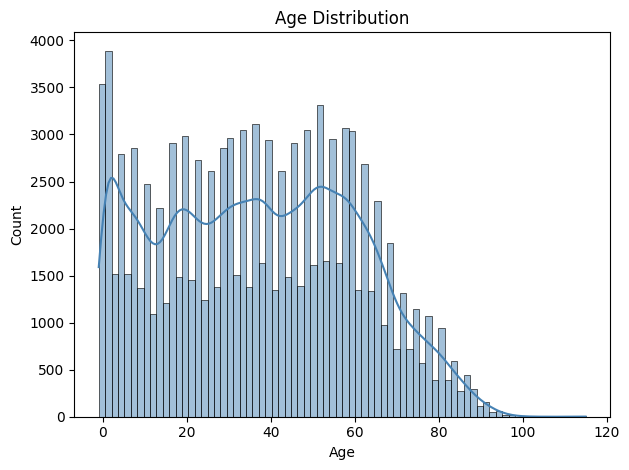

In [167]:
sns.histplot(df['Age'], kde= True, color= 'steelblue')
plt.title('Age Distribution')

plt.tight_layout()
plt.show()

In [168]:
# Drop negative age
df = df[df['Age']>=0]
df['Age'].min()

0

In [169]:
# Create age bins
categories = ['Young Child (0-4 YO)', 'Child (5-12 YO)', 'Teenager (13-16 YO)', 'Young Adult (17-24 YO)', 'Adult (25-63 YO)', 'Senior (>64 YO)']
df['age_group'] = pd.cut(df['Age'],
                         bins = [-1, 5, 13, 17, 25, 64, 116],
                         labels= categories, right=True)

df['age_group'].value_counts()

,count
age_group,
Adult (25-63 YO),57525
Senior (>64 YO),14402
Young Child (0-4 YO),11731
Young Adult (17-24 YO),11220
Child (5-12 YO),10408
Teenager (13-16 YO),5240


In [170]:
# Create new columns
df['day'] = df['Appointment_Day'].dt.day_name()
df['month'] = df['Appointment_Day'].dt.month_name()

def handicap_category(Handicap):
  if Handicap == 0:
    return 'No'
  else:
    return 'Yes'

df['handicap_category'] = df['Handicap'].apply(handicap_category)

# or df['handicap_category'] = df['Handicap'].apply(lambda x: 'No' if x == 0 else 'Yes')

df['waiting_days'] = (df['Appointment_Day'] - df['Scheduled_Day']).dt.days
df.head()

,Patient_Id,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighborhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,No_show,age_group,day,month,handicap_category,waiting_days
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,Adult (25-63 YO),Friday,April,No,-1
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,Adult (25-63 YO),Friday,April,No,-1
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,Adult (25-63 YO),Friday,April,No,-1
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,Child (5-12 YO),Friday,April,No,-1
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,Adult (25-63 YO),Friday,April,No,-1


In [171]:
(df['waiting_days']<0).value_counts()

,count
waiting_days,
False,71959
True,38567


In [172]:
# Drop negative waiting days
df = df[df['waiting_days'] >= 0]

In [173]:
df['waiting_days'].describe()

,waiting_days
count,71959.000000
mean,14.642018
std,16.494334
min,0.000000
25%,3.000000
50%,8.000000
75%,21.000000
max,178.000000


In [174]:
# Create waiting days bins
days_cat = ['Same day', '1-3 days', '4-7 days', '8-14 days','15-30 days', '+30 days']

df['waiting_group'] = pd.cut(df['waiting_days'],
                             bins= [-1, 0, 3, 7, 14, 30, 180],
                             labels = days_cat,
                             right=True)

df['waiting_group'].value_counts()

,count
waiting_group,
15-30 days,16540
1-3 days,14752
4-7 days,14552
8-14 days,11196
+30 days,9706
Same day,5213


In [175]:
# Overall no shows
no_show_values = df['No_show'].value_counts()
no_show_values

,count
No_show,
No,51437
Yes,20522


Text(0.5, 1.0, 'Overall No Show')

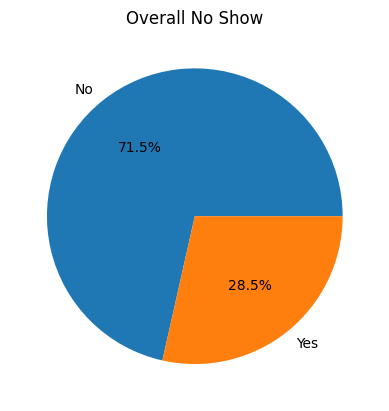

In [176]:
plt.pie(no_show_values, labels= no_show_values.index, autopct='%1.1f%%')
plt.title('Overall No Show')

In [177]:
for variable in df.columns.drop(['No_show', 'Patient_Id', 'Age', 'Appointment_ID', 'Scheduled_Day', 'Appointment_Day']):
  print(f'\n{variable} :')
  print(df.groupby([variable, 'No_show']).size().unstack(fill_value=0))


Gender :
No_show     No    Yes
Gender               
F        34396  13674
M        17041   6848

Neighborhood :
No_show                No  Yes
Neighborhood                  
AEROPORTO               4    1
ANDORINHAS           1033  491
ANTÔNIO HONÓRIO       137   43
ARIOVALDO FAVALESSA   118   57
BARRO VERMELHO        206   79
...                   ...  ...
SÃO JOSÉ             1003  373
SÃO PEDRO            1133  451
TABUAZEIRO           1398  526
UNIVERSITÁRIO          81   31
VILA RUBIM            462  136

[80 rows x 2 columns]

Scholarship :
No_show         No    Yes
Scholarship              
0            47099  18189
1             4338   2333

Hypertension :
No_show          No    Yes
Hypertension              
0             39941  16986
1             11496   3536

Diabetes :
No_show      No    Yes
Diabetes              
0         47402  19180
1          4035   1342

Alcoholism :
No_show        No    Yes
Alcoholism              
0           50236  19901
1            1201    621

/tmp/ipykernel_10070/4270575448.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby([variable, 'No_show']).size().unstack(fill_value=0))
/tmp/ipykernel_10070/4270575448.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby([variable, 'No_show']).size().unstack(fill_value=0))


In [178]:
# Visualization
'''variables = df.columns.drop([
    'No_show',
    'Patient_Id',
    'Age',
    'Appointment_ID',
    'Scheduled_Day',
    'Appointment_Day',
    'Neighborhood',
    'waiting_days'
])

for variable in variables:
  percentage = (df.groupby(variable)['No_show'].apply(lambda x: (x == 'Yes').mean() * 100))

  percentage.plot(kind='bar', figsize=(6, 4))
  plt.title(f'No Show Percentage by {variable}')
  plt.ylabel('No Shhow Percentage (%)')
  plt.xlabel(variable)

  plt.show()'''

"variables = df.columns.drop([\n    'No_show',\n    'Patient_Id',\n    'Age',\n    'Appointment_ID',\n    'Scheduled_Day',\n    'Appointment_Day', \n    'Neighborhood', \n    'waiting_days'\n])\n\nfor variable in variables:\n  percentage = (df.groupby(variable)['No_show'].apply(lambda x: (x == 'Yes').mean() * 100)) \n\n  percentage.plot(kind='bar', figsize=(6, 4))\n  plt.title(f'No Show Percentage by {variable}')\n  plt.ylabel('No Shhow Percentage (%)')\n  plt.xlabel(variable)\n\n  plt.show()"

/tmp/ipykernel_10070/2618112948.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  percentage = df.groupby(variable)['No_show'].apply(lambda x: (x == 'Yes').mean() * 100)
/tmp/ipykernel_10070/2618112948.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  percentage = df.groupby(variable)['No_show'].apply(lambda x: (x == 'Yes').mean() * 100)


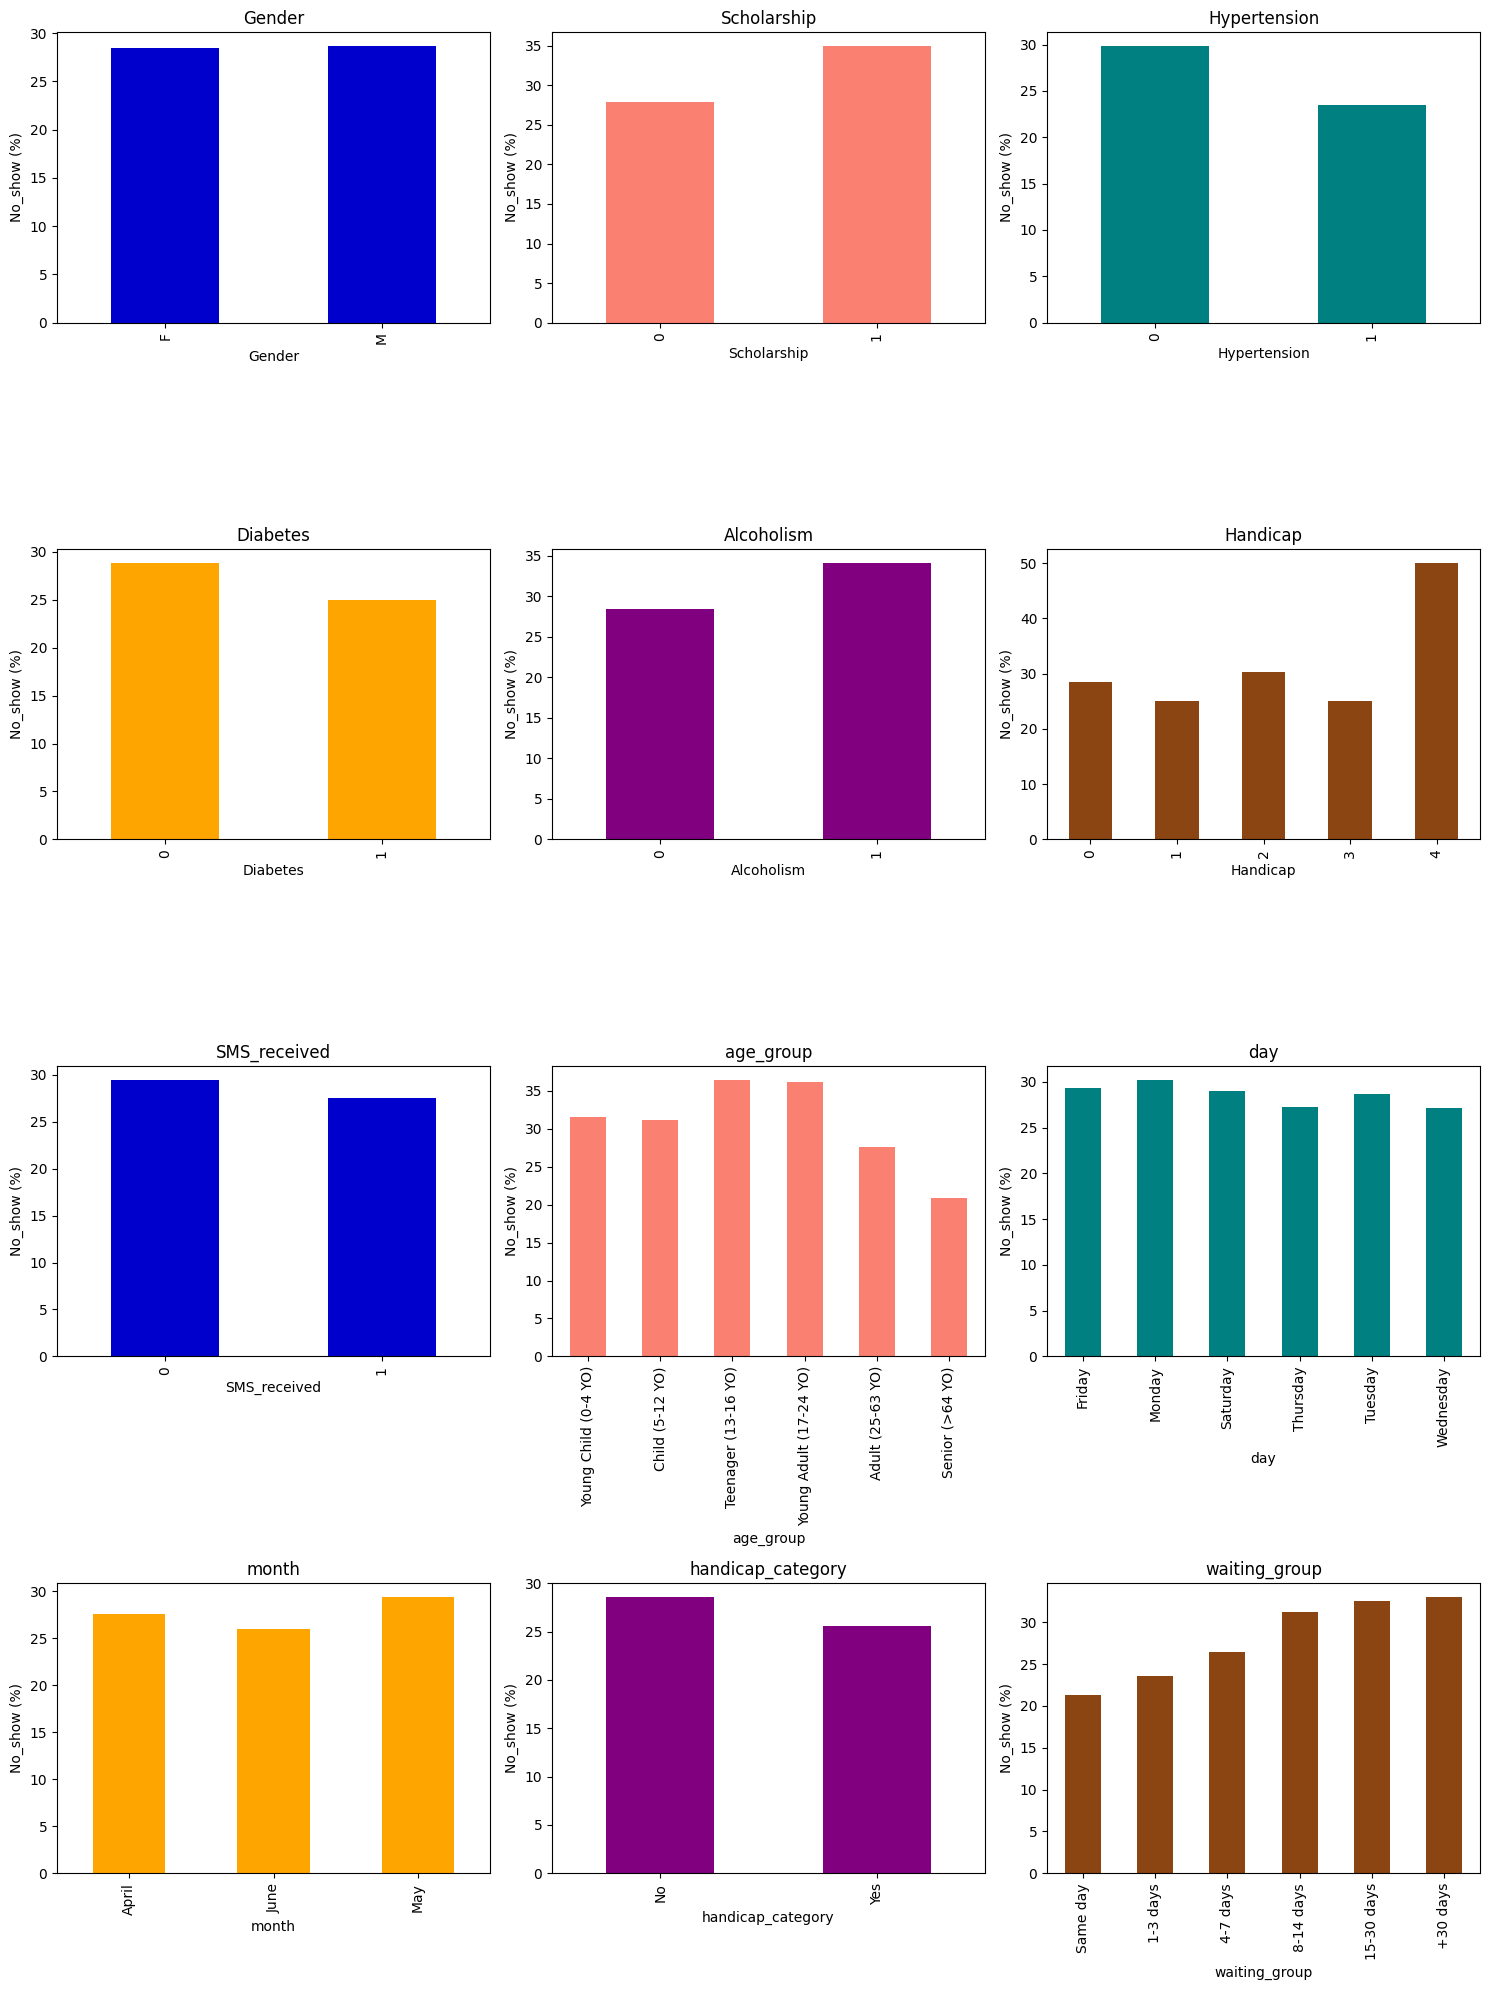

In [179]:
import math

variables = df.columns.drop([
    'No_show',
    'Patient_Id',
    'Age',
    'Appointment_ID',
    'Scheduled_Day',
    'Appointment_Day',
    'Neighborhood',
    'waiting_days'
])

ncols = 3
nrows = math.ceil(len(variables) / ncols)

colors = ['mediumblue', 'salmon', 'teal', 'orange', 'purple', 'saddlebrown']

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5 * nrows))

for i, variable in enumerate(variables):

    percentage = df.groupby(variable)['No_show'].apply(lambda x: (x == 'Yes').mean() * 100)

    percentage.plot(kind='bar', color=colors[i % len(colors)], ax=axes.flat[i])

    axes.flat[i].set_title(variable)
    axes.flat[i].set_ylabel('No_show (%)')
    axes.flat[i].set_xlabel(variable)

plt.tight_layout()
plt.show()


In [180]:
# Check the value counts of handicap and handicap group
print(df['Handicap'].value_counts().sort_index())
print(df['handicap_category'].value_counts())

Handicap
0    70652
1     1185
2      112
3        8
4        2
Name: count, dtype: int64
handicap_category
No     70652
Yes     1307
Name: count, dtype: int64


In [181]:
# Top 10 neighborhoods with the highest no show rate
neighborhood_rate = (df.groupby('Neighborhood')['No_show'].apply(lambda x: (x == 'Yes').mean() * 100)).sort_values(ascending=False).head(10)

# Top 5 neighborhoods with the highest number of no show
neighborhood_count = df[df['No_show'] == 'Yes']['Neighborhood'].value_counts().sort_values(ascending=False).head()

print('Top 10 neighborhoods with the highest no show rate:', neighborhood_rate)
print('Top 5 neighborhoods with the highest no show count:', neighborhood_count)

Top 10 neighborhoods with the highest no show rate: Neighborhood
ILHAS OCEÂNICAS DE TRINDADE    100.000000
GURIGICA                        38.371041
JESUS DE NAZARETH               37.492877
ITARARÉ                         36.497270
HORTO                           35.964912
SANTOS DUMONT                   34.891676
SANTA CLARA                     33.858268
SANTA CECÍLIA                   33.524355
ARIOVALDO FAVALESSA             32.571429
ILHA DO PRÍNCIPE                32.534930
Name: No_show, dtype: float64
Top 5 neighborhoods with the highest no show count: Neighborhood
JARDIM CAMBURI       1359
MARIA ORTIZ          1138
ITARARÉ               869
RESISTÊNCIA           857
JESUS DE NAZARETH     658
Name: count, dtype: int64


In [182]:
# Check how many times "ILHAS OCEÂNICAS DE TRINDADE" is present in the dataset
(df['Neighborhood'] == 'ILHAS OCEÂNICAS DE TRINDADE').value_counts()

,count
Neighborhood,
False,71957
True,2


In [183]:
# Top 5 neighborhoods rate with more than 30 appointments
neighborhood_rate = neighborhood_rate[df['Neighborhood'].value_counts()>30].sort_values(ascending=False).head()
print('Top 5 neighborhoods with the highest no show rate:', neighborhood_rate)

Top 5 neighborhoods with the highest no show rate: Neighborhood
GURIGICA             38.371041
JESUS DE NAZARETH    37.492877
ITARARÉ              36.497270
HORTO                35.964912
SANTOS DUMONT        34.891676
Name: No_show, dtype: float64


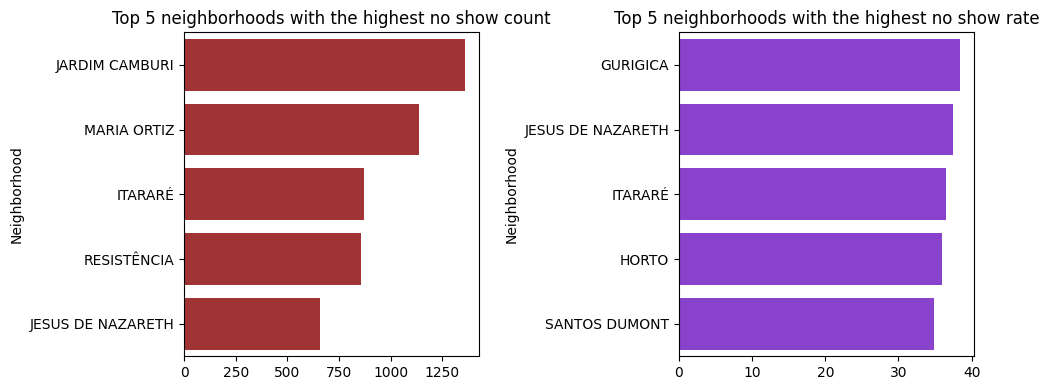

In [184]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.barplot(x = neighborhood_count.values, y = neighborhood_count.index, color='firebrick', ax=axes[0])
axes[0].set_title('Top 5 neighborhoods with the highest no show count')

sns.barplot(x = neighborhood_rate.values, y = neighborhood_rate.index, color='blueviolet', ax=axes[1])
axes[1].set_title('Top 5 neighborhoods with the highest no show rate')

plt.tight_layout()
plt.show()

In [185]:
df.head()

,Patient_Id,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighborhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,No_show,age_group,day,month,handicap_category,waiting_days,waiting_group
5,9.598513e+13,5626772,F,2016-04-27 08:36:51+00:00,2016-04-29 00:00:00+00:00,76,REPÚBLICA,0,1,0,0,0,0,No,Senior (>64 YO),Friday,April,No,1,1-3 days
6,7.336882e+14,5630279,F,2016-04-27 15:05:12+00:00,2016-04-29 00:00:00+00:00,23,GOIABEIRAS,0,0,0,0,0,0,Yes,Young Adult (17-24 YO),Friday,April,No,1,1-3 days
7,3.449833e+12,5630575,F,2016-04-27 15:39:58+00:00,2016-04-29 00:00:00+00:00,39,GOIABEIRAS,0,0,0,0,0,0,Yes,Adult (25-63 YO),Friday,April,No,1,1-3 days
9,7.812456e+13,5629123,F,2016-04-27 12:48:25+00:00,2016-04-29 00:00:00+00:00,19,CONQUISTA,0,0,0,0,0,0,No,Young Adult (17-24 YO),Friday,April,No,1,1-3 days
10,7.345362e+14,5630213,F,2016-04-27 14:58:11+00:00,2016-04-29 00:00:00+00:00,30,NOVA PALESTINA,0,0,0,0,0,0,No,Adult (25-63 YO),Friday,April,No,1,1-3 days


In [186]:
patient_no_show = df.groupby('Patient_Id')['No_show'].apply(lambda x: (x == 'Yes').sum())
patient_no_show.value_counts()

,count
No_show,
0,29217
1,13751
2,2203
3,457
4,135
5,43
6,18
7,7
8,5


**Analyse Patients history and no show risk**

In [187]:
df.head()

,Patient_Id,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighborhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,No_show,age_group,day,month,handicap_category,waiting_days,waiting_group
5,9.598513e+13,5626772,F,2016-04-27 08:36:51+00:00,2016-04-29 00:00:00+00:00,76,REPÚBLICA,0,1,0,0,0,0,No,Senior (>64 YO),Friday,April,No,1,1-3 days
6,7.336882e+14,5630279,F,2016-04-27 15:05:12+00:00,2016-04-29 00:00:00+00:00,23,GOIABEIRAS,0,0,0,0,0,0,Yes,Young Adult (17-24 YO),Friday,April,No,1,1-3 days
7,3.449833e+12,5630575,F,2016-04-27 15:39:58+00:00,2016-04-29 00:00:00+00:00,39,GOIABEIRAS,0,0,0,0,0,0,Yes,Adult (25-63 YO),Friday,April,No,1,1-3 days
9,7.812456e+13,5629123,F,2016-04-27 12:48:25+00:00,2016-04-29 00:00:00+00:00,19,CONQUISTA,0,0,0,0,0,0,No,Young Adult (17-24 YO),Friday,April,No,1,1-3 days
10,7.345362e+14,5630213,F,2016-04-27 14:58:11+00:00,2016-04-29 00:00:00+00:00,30,NOVA PALESTINA,0,0,0,0,0,0,No,Adult (25-63 YO),Friday,April,No,1,1-3 days


In [189]:
# Sort appointments chronologically
df = df.sort_values(['Patient_Id', 'Appointment_ID', 'Appointment_Day']).copy()

In [190]:
# Calculate prior appointments
df['prior_appointment'] = (df.groupby('Patient_Id').cumcount())

In [192]:
# Calculate prior no show
df['no_show_flag'] = (df['No_show'] == 'Yes').astype(int)

df['prior_no_shows'] = (df.groupby('Patient_Id')['no_show_flag'].transform(lambda x: x.cumsum().shift(1, fill_value = 0)))

In [193]:
# Calculate the prior no show rate
df['prior_no_show_rate'] = (df['prior_no_shows'] / df['prior_appointment'])

df.head()

,Patient_Id,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighborhood,Scholarship,Hypertension,Diabetes,...,age_group,day,month,handicap_category,waiting_days,waiting_group,prior_appointment,no_show_flag,prior_no_shows,prior_no_show_rate
100517,3.921784e+04,5751990,F,2016-05-31 10:56:41+00:00,2016-06-03 00:00:00+00:00,44,PRAIA DO SUÁ,0,0,0,...,Adult (25-63 YO),Friday,June,No,2,1-3 days,0,0,0,NaN
73303,1.417242e+05,5637648,M,2016-04-29 07:13:36+00:00,2016-05-02 00:00:00+00:00,12,FORTE SÃO JOÃO,0,0,0,...,Child (5-12 YO),Monday,May,No,2,1-3 days,0,0,0,NaN
73228,5.376153e+05,5637728,F,2016-04-29 07:19:57+00:00,2016-05-06 00:00:00+00:00,14,FORTE SÃO JOÃO,0,0,0,...,Teenager (13-16 YO),Friday,May,No,6,4-7 days,0,0,0,NaN
54611,5.628261e+06,5680449,M,2016-05-10 11:58:18+00:00,2016-05-13 00:00:00+00:00,13,PARQUE MOSCOSO,0,0,0,...,Child (5-12 YO),Friday,May,No,2,1-3 days,0,1,0,NaN
58616,2.263866e+07,5580835,F,2016-04-14 07:23:30+00:00,2016-05-03 00:00:00+00:00,22,INHANGUETÁ,0,0,0,...,Young Adult (17-24 YO),Tuesday,May,No,18,15-30 days,0,0,0,NaN


In [194]:
print(df['prior_no_show_rate'].value_counts())
print(df['prior_appointment'].value_counts())
print(df['prior_no_shows'].value_counts())

prior_no_show_rate
0.000000    15770
1.000000     5330
0.500000     2027
0.333333      858
0.250000      424
            ...  
0.117647        1
0.157895        1
0.636364        1
0.583333        1
0.818182        1
Name: count, Length: 73, dtype: int64
prior_appointment
0     45840
1     14719
2      5512
3      2440
4      1256
5       716
6       444
7       298
8       212
9       167
10      107
11       77
12       56
13       36
14       22
15       16
16       12
17        8
18        7
19        4
20        1
21        1
22        1
23        1
24        1
25        1
26        1
27        1
28        1
29        1
Name: count, dtype: int64
prior_no_shows
0     61610
1      7928
2      1657
3       490
4       162
5        62
6        23
7        15
8         4
9         4
10        4
Name: count, dtype: int64


In [195]:
# Create risk category
df['Risk'] = ''

for index, row in df.iterrows():

  if row['prior_appointment'] == 0:
    df.loc[index, 'Risk'] = 'New Patient'

  elif row['prior_no_show_rate'] >= 0.2 or 4 <= row['waiting_days'] >= 7:
    df.loc[index, 'Risk'] = 'Medium Risk'

  elif row['prior_no_show_rate'] >= 0.5 or row['waiting_days'] >= 8:
    df.loc[index, 'Risk'] = 'High Risk'

  else:
    df.loc[index, 'Risk'] = 'Low Risk'

In [196]:
df.head()

,Patient_Id,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighborhood,Scholarship,Hypertension,Diabetes,...,day,month,handicap_category,waiting_days,waiting_group,prior_appointment,no_show_flag,prior_no_shows,prior_no_show_rate,Risk
100517,3.921784e+04,5751990,F,2016-05-31 10:56:41+00:00,2016-06-03 00:00:00+00:00,44,PRAIA DO SUÁ,0,0,0,...,Friday,June,No,2,1-3 days,0,0,0,NaN,New Patient
73303,1.417242e+05,5637648,M,2016-04-29 07:13:36+00:00,2016-05-02 00:00:00+00:00,12,FORTE SÃO JOÃO,0,0,0,...,Monday,May,No,2,1-3 days,0,0,0,NaN,New Patient
73228,5.376153e+05,5637728,F,2016-04-29 07:19:57+00:00,2016-05-06 00:00:00+00:00,14,FORTE SÃO JOÃO,0,0,0,...,Friday,May,No,6,4-7 days,0,0,0,NaN,New Patient
54611,5.628261e+06,5680449,M,2016-05-10 11:58:18+00:00,2016-05-13 00:00:00+00:00,13,PARQUE MOSCOSO,0,0,0,...,Friday,May,No,2,1-3 days,0,1,0,NaN,New Patient
58616,2.263866e+07,5580835,F,2016-04-14 07:23:30+00:00,2016-05-03 00:00:00+00:00,22,INHANGUETÁ,0,0,0,...,Tuesday,May,No,18,15-30 days,0,0,0,NaN,New Patient


In [197]:
df['Risk'].value_counts()

,count
Risk,
New Patient,45840
Medium Risk,16864
Low Risk,9255
